# Modelos de Clasificación: Predicción de Abandono de Clientes Bancarios (Churn)


**Objetivos de aprendizaje.** Al terminar este notebook podrás:
1. Realizar un análisis exploratorio (EDA) orientado a un problema de clasificación desbalanceado.
2. Diseñar variables nuevas (*feature engineering*) y medir si realmente aportan.
3. Entrenar, explicar y comparar cinco clasificadores: **regresión logística, árbol de decisión, Random Forest, XGBoost y una red neuronal**.
4. Elegir métricas adecuadas (AUC-ROC, precisión, recall, F1) y un **umbral de decisión** con criterio de negocio.
5. Diagnosticar sobreajuste con **curvas de entrenamiento** y **curvas de aprendizaje**.
6. Analizar la **sensibilidad de los hiperparámetros**



# 1. Caso de negocio: retener clientes antes de que se vayan

**Contexto.** Un banco pierde clientes todos los meses. Conseguir un cliente nuevo suele costar mucho más que conservar uno existente, por lo que el área comercial quiere **contactar con una oferta de retención** (mejor tasa, beneficios, asesor personal) a los clientes con mayor riesgo de abandono.

**Problema de aprendizaje automático.** Clasificación binaria: dado el perfil de un cliente, predecir `Exited` (1 = abandona, 0 = permanece).

**¿Por qué no basta con la exactitud (*accuracy*)?**
- La clase "abandona" es **minoritaria** (alrededor de uno de cada cinco clientes). Un modelo que siempre responda "permanece" tendría una exactitud alta y sería inútil.
- Los dos errores no cuestan lo mismo:
  - **Falso negativo** (el cliente se iba y no lo detectamos): se pierde el cliente y todo su valor futuro.
  - **Falso positivo** (ofrecemos retención a quien no se iba): se gasta presupuesto de campaña en vano.

Por eso evaluaremos con **AUC-ROC** (métrica oficial de la competencia de Kaggle de la que proviene el dataset), **precisión, recall y F1**, y al final traduciremos el modelo a **valor económico** eligiendo el umbral de decisión según el costo de la campaña.

**Criterio de éxito:** un modelo es útil para la campaña si ordena a los clientes por riesgo mucho mejor que el azar (AUC-ROC claramente superior a 0.5) y si, con un umbral bien elegido, la campaña genera beneficio neto positivo.

# 2. Librerías

In [3]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, roc_curve, precision_recall_curve)
from xgboost import XGBClassifier

%matplotlib inline
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

# 3. Datos

Usaremos el dataset de la competencia de Kaggle **Binary Classification with a Synthetic Bank Churn Dataset**. Es un conjunto **sintético** (generado con un modelo de aprendizaje profundo a partir de datos reales de clientes bancarios), con la misma estructura que el conjunto original.



In [4]:
df = pd.read_csv('sample_data/train.csv')
df.head()

,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15617156.0,Chia,593.0,France,Male,46.0,9.0,0.00,2.0,1.0,1.0,83629.60,0.0
1,1,15607988.0,Yeh,539.0,France,Female,33.0,3.0,0.00,2.0,0.0,1.0,73979.86,0.0
2,2,15626383.0,Ch'ien,709.0,Spain,Male,21.0,2.0,0.00,2.0,0.0,1.0,25669.10,0.0
3,3,15583392.0,Palerma,628.0,Germany,Female,33.0,4.0,109342.82,1.0,1.0,1.0,67611.36,0.0
4,4,15775300.0,Palerma,640.0,France,Male,34.0,9.0,127545.99,1.0,1.0,1.0,147545.65,0.0


**Diccionario de variables**

| Variable | Descripción |
|---|---|
| `id` | Identificador de la fila (no aporta información predictiva) |
| `CustomerId` | Identificador del cliente |
| `Surname` | Apellido del cliente |
| `CreditScore` | Puntaje crediticio |
| `Geography` | País de residencia (France, Spain, Germany) |
| `Gender` | Género |
| `Age` | Edad en años |
| `Tenure` | Años que lleva como cliente del banco |
| `Balance` | Saldo de la cuenta |
| `NumOfProducts` | Número de productos bancarios contratados |
| `HasCrCard` | Tiene tarjeta de crédito (1 = sí, 0 = no) |
| `IsActiveMember` | Es un cliente activo (1 = sí, 0 = no) |
| `EstimatedSalary` | Salario estimado |
| **`Exited`** | **Variable objetivo:** 1 = el cliente abandonó el banco, 0 = permanece |

# 4. Análisis Exploratorio de Datos (EDA)

El EDA se hace **antes de modelar** y responde cuatro preguntas: ¿qué calidad tienen los datos?, ¿qué tan desbalanceada está la variable objetivo?, ¿cómo se comporta cada variable?, y sobre todo, ¿**qué variables parecen relacionarse con el abandono**? Sus conclusiones guiarán el *feature engineering*.

## 4.1 Calidad de los datos

In [5]:
print(f'Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}')

calidad = pd.DataFrame({
    'Tipo': df.dtypes.astype(str),
    'Faltantes': df.isnull().sum(),
    '% Faltante': (df.isnull().mean() * 100).round(2),
    'Valores únicos': df.nunique(),
})
display(calidad)

print('Filas duplicadas:', df.duplicated().sum())
print(f"Clientes únicos (CustomerId): {df['CustomerId'].nunique():,} de {len(df):,} filas")

Filas: 15,000 | Columnas: 14


,Tipo,Faltantes,% Faltante,Valores únicos
id,int64,0,0.0,15000
CustomerId,float64,0,0.0,6318
Surname,object,0,0.0,753
CreditScore,float64,0,0.0,374
Geography,object,0,0.0,3
Gender,object,0,0.0,2
Age,float64,0,0.0,54
Tenure,float64,0,0.0,11
Balance,float64,0,0.0,3264
NumOfProducts,float64,0,0.0,5


Filas duplicadas: 0
Clientes únicos (CustomerId): 6,318 de 15,000 filas


**Qué mirar aquí.** Si hay valores faltantes se deben imputar o eliminar antes de modelar. Observa también el número de valores únicos: `id` es único por fila (un identificador puro), `CustomerId` y `Surname` son identificadores o textos con alta cardinalidad. Si `CustomerId` aparece repetido, significa que **un mismo cliente figura en varias filas**, algo que debemos recordar al hacer la partición de datos.

## 4.2 Estadísticas descriptivas

In [6]:
df.drop(columns=['id', 'CustomerId']).describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
CreditScore,15000.0,657.85,73.01,434.00,599.00,660.00,708.00,850.00
Age,15000.0,37.85,8.18,18.00,32.00,37.00,42.00,72.00
Tenure,15000.0,5.01,2.80,0.00,3.00,5.00,7.00,10.00
Balance,15000.0,42660.95,61118.14,0.00,0.00,0.00,110262.41,1648401.32
NumOfProducts,15000.0,1.59,0.53,1.00,1.00,2.00,2.00,5.00
HasCrCard,15000.0,0.78,0.41,0.00,1.00,1.00,1.00,1.00
IsActiveMember,15000.0,0.49,0.50,0.00,0.00,0.00,1.00,1.00
EstimatedSalary,15000.0,117634.67,47113.50,447.73,83010.35,122547.58,155876.06,1648224.11
Exited,15000.0,0.21,0.41,0.00,0.00,0.00,0.00,1.00


**Qué mirar aquí.** Rangos y escalas muy distintos entre variables (por ejemplo, `Balance` y `EstimatedSalary` frente a `Tenure`) son relevantes para modelos sensibles a la escala, como la regresión logística y las redes neuronales; los modelos basados en árboles no los necesitan. Busca también valores imposibles (edades negativas, saldos negativos).

## 4.3 Variable objetivo: ¿qué tan desbalanceada está?

,Clientes,% del total
Exited,,
0.0,11896,79.31
1.0,3104,20.69


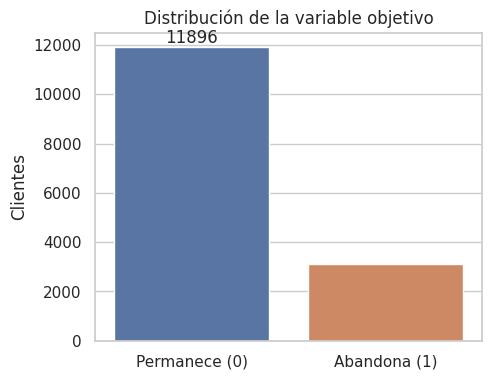

In [7]:
conteo = df['Exited'].value_counts()
display(pd.DataFrame({'Clientes': conteo, '% del total': (conteo / len(df) * 100).round(2)}))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x='Exited', data=df, ax=ax, palette=['#4C72B0', '#DD8452'])
ax.set_xticklabels(['Permanece (0)', 'Abandona (1)'])
ax.set_xlabel('')
ax.set_ylabel('Clientes')
ax.set_title('Distribución de la variable objetivo')
ax.bar_label(ax.containers[0], fmt='%d')
plt.show()

**Decisión.** Como la clase "abandona" es minoritaria: (1) usaremos una partición **estratificada** (conserva la proporción de clases en entrenamiento y prueba) y (2) evaluaremos con **AUC-ROC, AUC-PR, precisión, recall y F1**, no solo con exactitud.

## 4.4 Variables numéricas: distribución según el abandono
Comparamos la distribución de cada variable entre quienes se quedan y quienes se van. Si las dos curvas son casi idénticas, la variable aporta poca información; si se separan, es una pista valiosa.

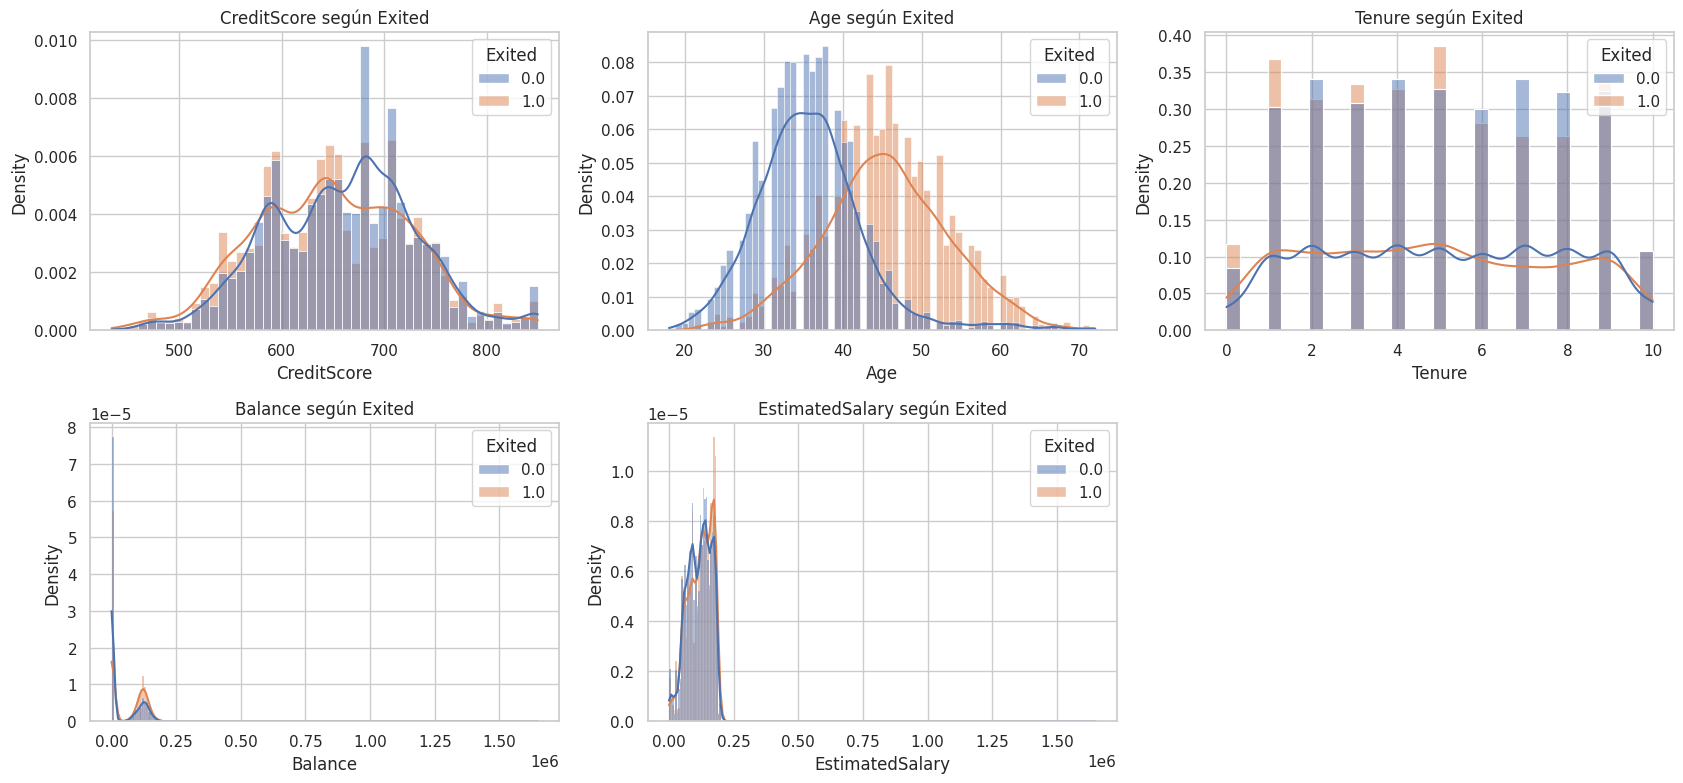

In [9]:
num_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary']

fig, axes = plt.subplots(2, 3, figsize=(17, 8))
axes = axes.flatten()
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue='Exited', kde=True, stat='density', common_norm=False,
                 palette=['#4C72B0', '#DD8452'], ax=ax)
    ax.set_title(f'{col} según Exited')
fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()

**Cómo leerlo.** Fíjate en qué variables muestran curvas claramente desplazadas entre clientes que abandonan (naranja) y que permanecen (azul), y cuáles se superponen. Presta atención especial a `Balance` (¿hay un grupo grande con saldo exactamente cero?) y a `Age` (¿la relación con el abandono es lineal o tiene forma de campana?).

## 4.5 Variables categóricas y discretas: tasa de abandono por categoría
La línea roja es la tasa de abandono global; las barras por encima de ella señalan grupos con mayor riesgo.

In [11]:
df['Exited'].mean()

np.float64(0.20693333333333333)

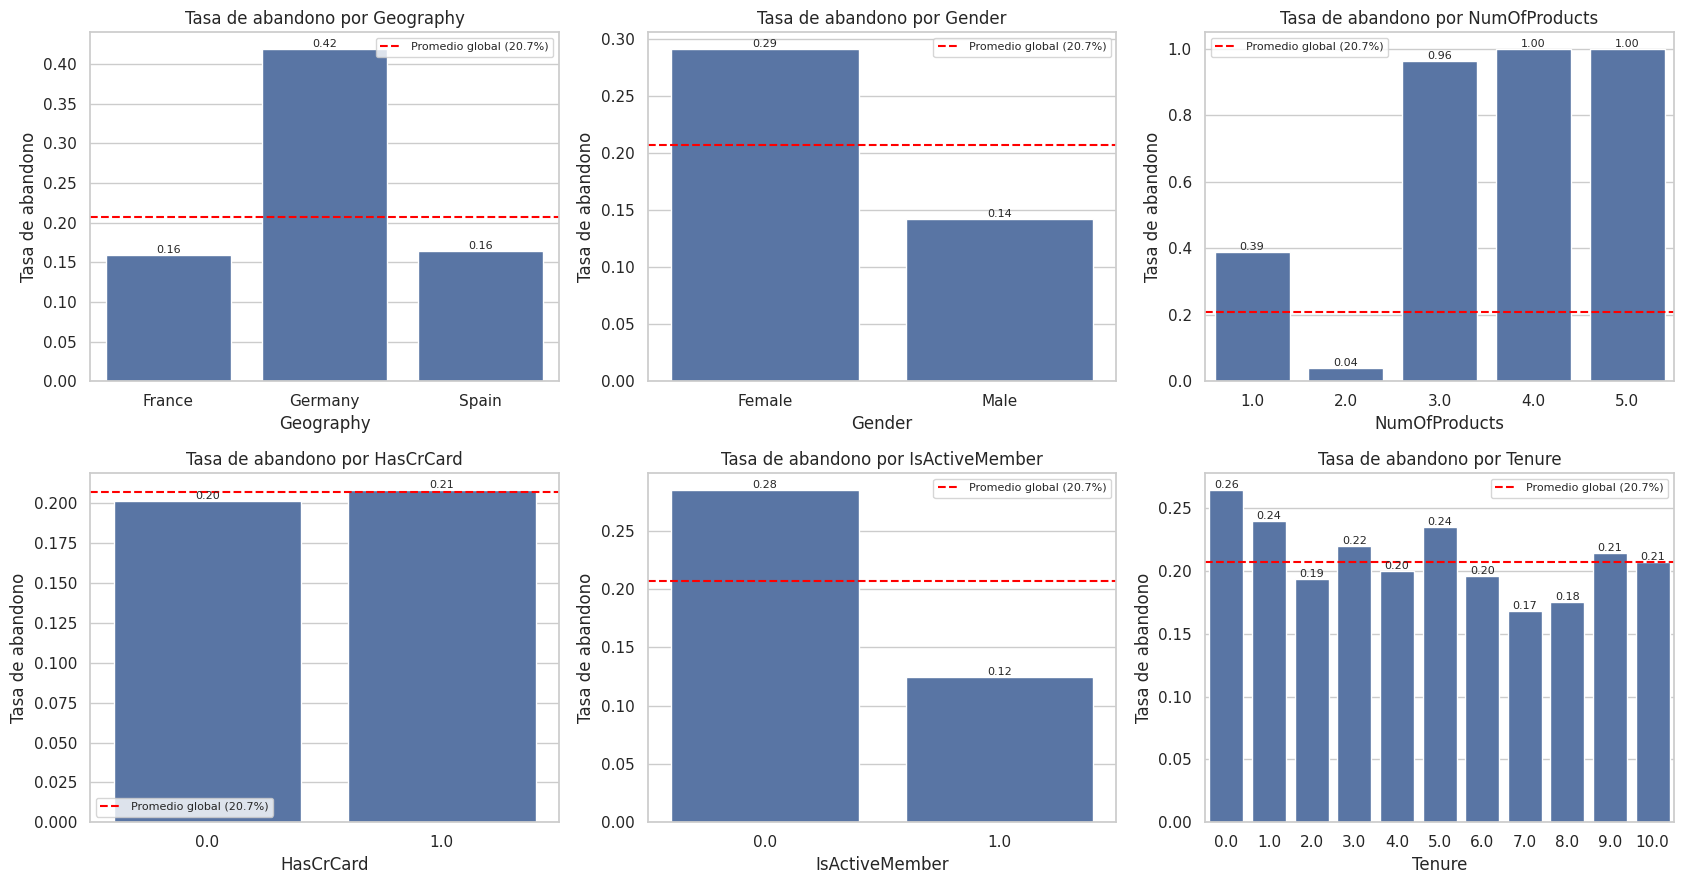

In [10]:
cat_cols = ['Geography', 'Gender', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'Tenure']
tasa_global = df['Exited'].mean()

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
axes = axes.flatten()
for ax, col in zip(axes, cat_cols):
    tasa = df.groupby(col)['Exited'].mean().reset_index()
    sns.barplot(data=tasa, x=col, y='Exited', ax=ax, color='#4C72B0')
    ax.axhline(tasa_global, color='red', ls='--', label=f'Promedio global ({tasa_global:.1%})')
    ax.set_title(f'Tasa de abandono por {col}')
    ax.set_ylabel('Tasa de abandono')
    ax.bar_label(ax.containers[0], fmt='%.2f', fontsize=8)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Cómo leerlo.** Las diferencias grandes entre categorías (barras muy por encima o por debajo de la línea roja) señalan variables potentes. Compara en particular `NumOfProducts`, `IsActiveMember` y `Geography`. Una categoría con muy pocos clientes puede mostrar tasas extremas por azar, así que revisa también cuántos clientes tiene cada grupo.

## 4.6 Edad y saldo: dos relaciones que no son lineales

,Clientes,Tasa_abandono
Age,,
<30,2448,0.040
30-39,7890,0.092
40-49,3491,0.425
50-59,941,0.738
60+,230,0.439


,Clientes,Tasa_abandono
Balance = 0,9776,0.162
Balance > 0,5224,0.292


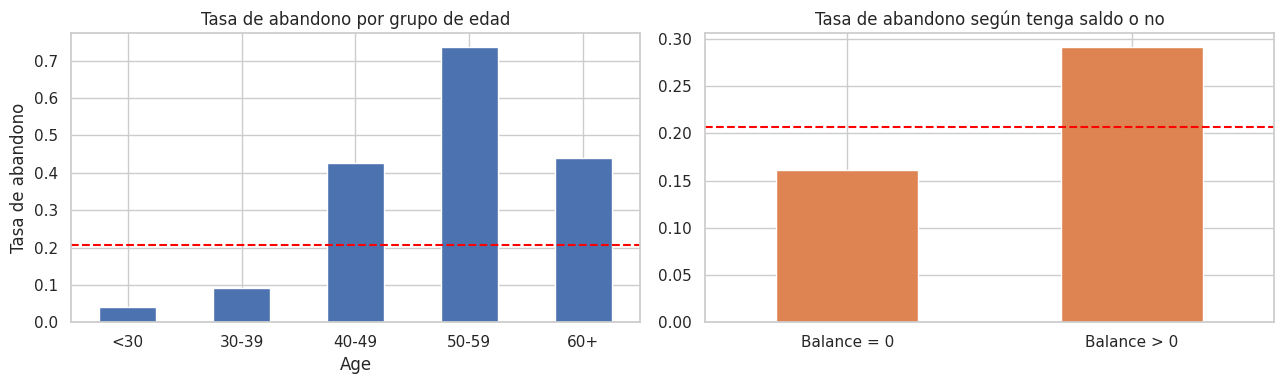

In [12]:
grupo_edad = pd.cut(df['Age'], bins=[0, 30, 40, 50, 60, 120],
                    labels=['<30', '30-39', '40-49', '50-59', '60+'])
tasa_edad = df.groupby(grupo_edad, observed=False)['Exited'].agg(Clientes='count', Tasa_abandono='mean')

saldo_cero = df.groupby(np.where(df['Balance'] == 0, 'Balance = 0', 'Balance > 0'))['Exited'] \
               .agg(Clientes='count', Tasa_abandono='mean')

display(tasa_edad.round(3))
display(saldo_cero.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
tasa_edad['Tasa_abandono'].plot(kind='bar', ax=axes[0], color='#4C72B0', rot=0)
axes[0].axhline(tasa_global, color='red', ls='--')
axes[0].set_title('Tasa de abandono por grupo de edad')
axes[0].set_ylabel('Tasa de abandono')
saldo_cero['Tasa_abandono'].plot(kind='bar', ax=axes[1], color='#DD8452', rot=0)
axes[1].axhline(tasa_global, color='red', ls='--')
axes[1].set_title('Tasa de abandono según tenga saldo o no')
plt.tight_layout()
plt.show()

**Idea clave.** Si la tasa de abandono no sube ni baja de forma constante con la edad (por ejemplo, crece hasta cierto tramo y luego cae), hay una **relación no lineal**: un modelo lineal no puede capturarla con la variable `Age` cruda, pero sí con grupos de edad. De forma parecida, tener saldo cero o no puede ser más informativo que el valor exacto del saldo. Esto motiva el *feature engineering* de la siguiente sección.

## 4.7 Correlaciones

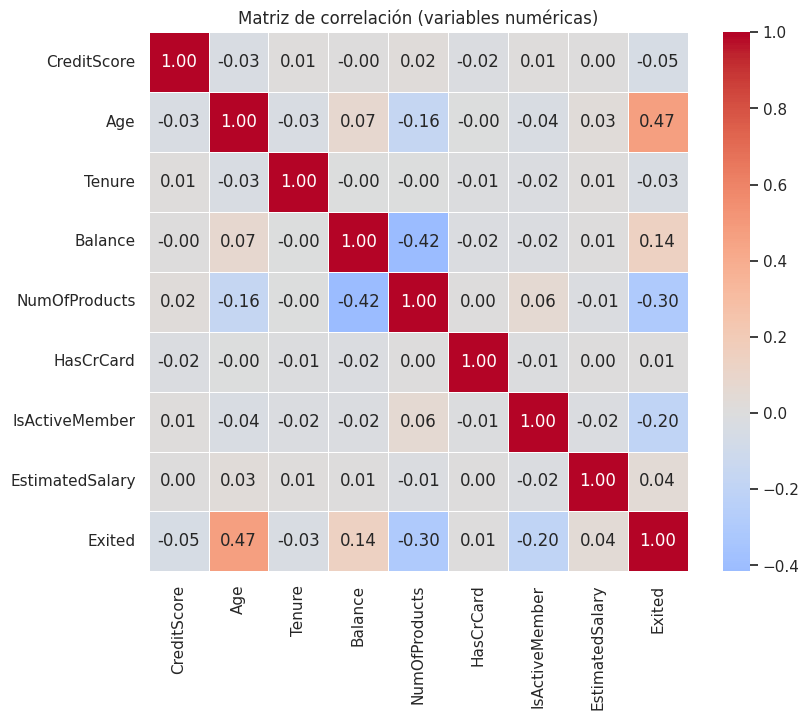

,Correlación con Exited
Age,0.471
NumOfProducts,-0.298
IsActiveMember,-0.198
Balance,0.144
CreditScore,-0.054
EstimatedSalary,0.043
Tenure,-0.031
HasCrCard,0.007


In [13]:
num_df = df.drop(columns=['id', 'CustomerId', 'Surname', 'Geography', 'Gender'])
corr = num_df.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, linewidths=0.5)
plt.title('Matriz de correlación (variables numéricas)')
plt.show()

display(corr['Exited'].drop('Exited').sort_values(key=abs, ascending=False)
        .to_frame('Correlación con Exited').round(3))

**Cómo leerla.** La correlación de Pearson solo mide relaciones **lineales**. Una variable puede tener correlación cercana a cero con `Exited` y aun así ser muy útil (por ejemplo, si su efecto tiene forma de campana, como a veces ocurre con la edad). Por eso no descartamos variables solo por su correlación.

## 4.8 Valores atípicos (outliers)

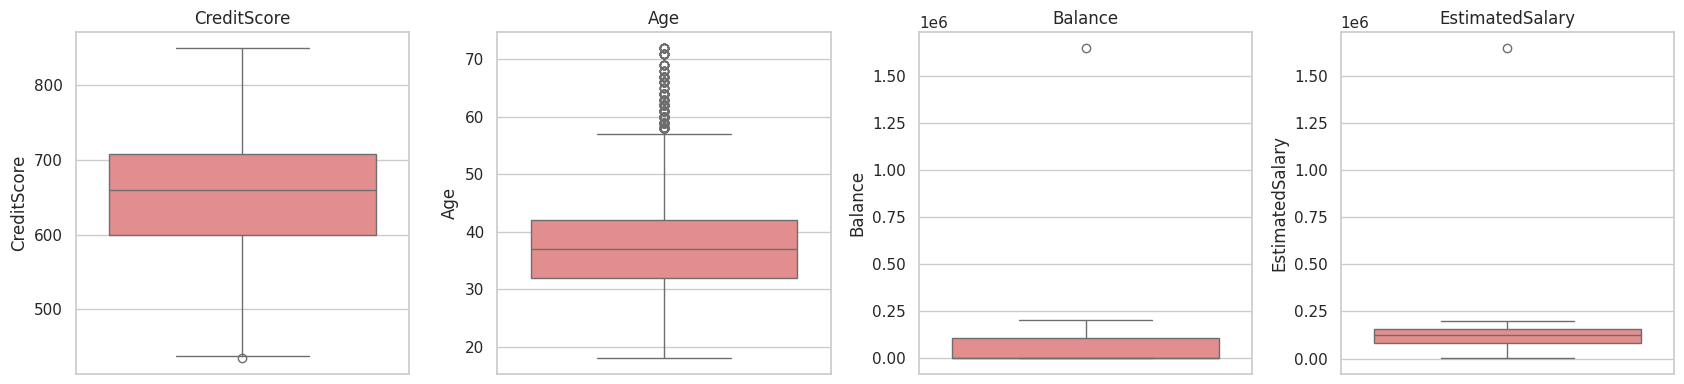

,Outliers (regla IQR)
CreditScore,1
Age,409
Balance,1
EstimatedSalary,1


In [15]:
out_cols = ['CreditScore', 'Age', 'Balance', 'EstimatedSalary']

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, col in zip(axes, out_cols):
    sns.boxplot(y=df[col], ax=ax, color='lightcoral')
    ax.set_title(col)
plt.tight_layout()
plt.show()

def contar_outliers_iqr(serie):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    return int(((serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)).sum())

pd.DataFrame({'Outliers (regla IQR)': {c: contar_outliers_iqr(df[c]) for c in out_cols}})

## 4.9 Conclusiones del EDA y decisiones

| Hallazgo a verificar en los gráficos | Decisión |
|---|---|
| `id`, `CustomerId` y `Surname` son identificadores o textos con muchísimos valores distintos | Se **eliminan**: un modelo no debe aprender a "reconocer" clientes, solo patrones generalizables |
| Clase "abandona" minoritaria | Partición **estratificada** y métricas robustas al desbalance (AUC-ROC, AUC-PR, recall, F1) |
| Efecto no lineal de la edad | Crear **grupos de edad** |
| Saldo con un grupo grande en cero | Crear la bandera **`Has_Balance`** y razones entre saldo y salario |
| Pocos clientes con 3 o más productos pero con comportamiento muy distinto | Crear la bandera **`Many_Products`** |
| `Geography` y `Gender` son categóricas | **Codificación one-hot** |
| Escalas muy distintas entre variables | **Estandarizar** solo para regresión logística y red neuronal |
| Outliers moderados | Se **conservan**: los modelos de árboles son robustos y no hay evidencia de errores de captura |

# 5. Feature Engineering (ingeniería de variables)

Crear buenas variables suele aportar más que cambiar de algoritmo. Construiremos variables a partir de lo que vimos en el EDA:

| Variable nueva | Idea |
|---|---|
| `Has_Balance` | ¿El cliente tiene saldo? (1 si `Balance` > 0) |
| `Balance_Salary_Ratio` | Saldo relativo al ingreso: qué tan "pesado" es su dinero en el banco |
| `Tenure_Age_Ratio` | Proporción de su vida que lleva como cliente (fidelidad relativa) |
| `CreditScore_Age_Ratio` | Puntaje crediticio relativo a la edad |
| `Many_Products` | 1 si tiene 3 o más productos |
| `Active_Products` | Interacción: miembro activo × número de productos |
| `Age_Group` | Grupos de edad (captura el efecto no lineal) |
| One-hot de `Geography`, `Gender`, `Age_Group` | Convierte categorías en columnas numéricas |

**¿Hay fuga de datos (*data leakage*) al crear estas variables antes de partir los datos?** No: todas son transformaciones **fila por fila** que no calculan estadísticos globales (medias, desviaciones, etc.). Lo que sí requiere aprender de los datos de entrenamiento, como la estandarización, se hará **después** de la partición y solo con el conjunto de entrenamiento.

In [16]:
def crear_features(data):
    d = data.copy()
    d = d.drop(columns=['id', 'CustomerId', 'Surname'], errors='ignore')

    d['Has_Balance'] = (d['Balance'] > 0).astype(int)
    d['Balance_Salary_Ratio'] = d['Balance'] / (d['EstimatedSalary'] + 1)
    d['Tenure_Age_Ratio'] = d['Tenure'] / d['Age']
    d['CreditScore_Age_Ratio'] = d['CreditScore'] / d['Age']
    d['Many_Products'] = (d['NumOfProducts'] >= 3).astype(int)
    d['Active_Products'] = d['IsActiveMember'] * d['NumOfProducts']
    d['Age_Group'] = pd.cut(d['Age'], bins=[0, 30, 40, 50, 60, 120],
                            labels=['<30', '30-39', '40-49', '50-59', '60+'])

    return pd.get_dummies(d, columns=['Geography', 'Gender', 'Age_Group'], drop_first=True, dtype=int)

y = df['Exited']
X = crear_features(df.drop(columns=['Exited']))

# Versión "base" (solo codificación, sin variables nuevas) para medir el aporte del feature engineering
X_base = pd.get_dummies(df.drop(columns=['Exited', 'id', 'CustomerId', 'Surname']),
                        columns=['Geography', 'Gender'], drop_first=True, dtype=int)

print(f'Variables originales útiles: {X_base.shape[1]} | Variables con feature engineering: {X.shape[1]}')
X.head()

Variables originales útiles: 11 | Variables con feature engineering: 21


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Has_Balance,Balance_Salary_Ratio,...,CreditScore_Age_Ratio,Many_Products,Active_Products,Geography_Germany,Geography_Spain,Gender_Male,Age_Group_30-39,Age_Group_40-49,Age_Group_50-59,Age_Group_60+
0,593.0,46.0,9.0,0.00,2.0,1.0,1.0,83629.60,0,0.000000,...,12.891304,0,2.0,0,0,1,0,1,0,0
1,539.0,33.0,3.0,0.00,2.0,0.0,1.0,73979.86,0,0.000000,...,16.333333,0,2.0,0,0,0,1,0,0,0
2,709.0,21.0,2.0,0.00,2.0,0.0,1.0,25669.10,0,0.000000,...,33.761905,0,2.0,0,1,1,0,0,0,0
3,628.0,33.0,4.0,109342.82,1.0,1.0,1.0,67611.36,1,1.617202,...,19.030303,0,1.0,1,0,0,1,0,0,0
4,640.0,34.0,9.0,127545.99,1.0,1.0,1.0,147545.65,1,0.864445,...,18.823529,0,1.0,0,0,1,1,0,0,0


# 6. Partición de los datos

Dividimos en **80 % entrenamiento y 20 % prueba**, de forma **estratificada**. El conjunto de prueba se usa **una sola vez**, al final, para estimar el desempeño real. Para las decisiones intermedias (parada temprana, afinación de hiperparámetros) separamos además una parte del entrenamiento como **validación**.

> **Nota sobre los clientes repetidos:** si `CustomerId` aparece en varias filas, es posible que un mismo cliente caiga en entrenamiento y en prueba, lo que puede hacer que las métricas salgan algo optimistas. En un proyecto real conviene particionar por cliente (por ejemplo, con `GroupShuffleSplit`). Aquí mantenemos la partición estratificada por simplicidad didáctica.

In [17]:
idx_train, idx_test = train_test_split(df.index, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

X_train, X_test = X.loc[idx_train], X.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

# Validación: 15 % del entrenamiento (para parada temprana, curvas y sensibilidad)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.15,
                                            stratify=y_train, random_state=RANDOM_STATE)

resumen_split = pd.DataFrame({
    'Filas': [len(X_tr), len(X_val), len(X_test)],
    '% de abandono': [y_tr.mean() * 100, y_val.mean() * 100, y_test.mean() * 100],
}, index=['Entrenamiento (tr)', 'Validación (val)', 'Prueba (test)']).round(2)
resumen_split

,Filas,% de abandono
Entrenamiento (tr),10200,20.70
Validación (val),1800,20.67
Prueba (test),3000,20.70


In [18]:
y_test.value_counts()

,count
Exited,
0.0,2379
1.0,621


In [20]:
2379/(2379+621)

0.793

## 6.1 ¿Valió la pena el feature engineering?
Comparamos, con la **misma partición**, un modelo entrenado con las variables originales frente a uno con las variables nuevas. Usamos AUC-ROC en el conjunto de **validación**.

In [21]:
def pipeline_logistica():
    return Pipeline([('scaler', StandardScaler()),
                     ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])

def auc_val(modelo, Xa, Xb):
    modelo.fit(Xa, y.loc[Xa.index])
    return roc_auc_score(y.loc[Xb.index], modelo.predict_proba(Xb)[:, 1])

Xb_tr, Xb_val = X_base.loc[X_tr.index], X_base.loc[X_val.index]

ablacion = pd.DataFrame({
    'Regresión logística': [auc_val(pipeline_logistica(), Xb_tr, Xb_val),
                            auc_val(pipeline_logistica(), X_tr, X_val)],
    'XGBoost (150 árboles)': [
        auc_val(XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.1, tree_method='hist',
                              random_state=RANDOM_STATE), Xb_tr, Xb_val),
        auc_val(XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.1, tree_method='hist',
                              random_state=RANDOM_STATE), X_tr, X_val)],
}, index=['Variables originales', 'Con feature engineering'])
ablacion.loc['Mejora (AUC)'] = ablacion.loc['Con feature engineering'] - ablacion.loc['Variables originales']
ablacion.round(4)

,Regresión logística,XGBoost (150 árboles)
Variables originales,0.8864,0.9325
Con feature engineering,0.9287,0.9322
Mejora (AUC),0.0424,-0.0003


**Cómo leerlo.** Los modelos lineales suelen beneficiarse mucho de variables que capturan relaciones no lineales (grupos de edad, banderas), mientras que los modelos de árboles ya descubren por sí solos muchas de esas relaciones, por lo que la mejora suele ser menor. Esto ilustra una idea importante: **el feature engineering compensa las limitaciones del modelo**.

# 7. Cómo medir un clasificador

Todo clasificador produce una **probabilidad** de pertenecer a la clase positiva (abandona). Para tomar una decisión se fija un **umbral** (por defecto 0.5): si la probabilidad lo supera, se predice "abandona".

**Matriz de confusión** (clase positiva = abandona):

| | Predice "permanece" | Predice "abandona" |
|---|---|---|
| **Real: permanece** | Verdadero negativo (TN) | Falso positivo (FP) |
| **Real: abandona** | Falso negativo (FN) | Verdadero positivo (TP) |

**Métricas derivadas:**

$$ \text{Exactitud} = \frac{TP + TN}{TP + TN + FP + FN} \qquad \text{Precisión} = \frac{TP}{TP + FP} \qquad \text{Recall} = \frac{TP}{TP + FN} $$

$$ F1 = 2 \cdot \frac{\text{Precisión} \cdot \text{Recall}}{\text{Precisión} + \text{Recall}} $$

- **Precisión:** de los clientes que marcamos como "se irán", ¿qué proporción realmente se iba? (costo de los falsos positivos).
- **Recall (sensibilidad):** de los clientes que realmente se iban, ¿qué proporción detectamos? (costo de los falsos negativos).
- **AUC-ROC:** probabilidad de que el modelo asigne mayor riesgo a un cliente que abandona que a uno que se queda; **no depende del umbral**. 0.5 equivale al azar; 1.0 es perfecto.
- **AUC-PR:** área bajo la curva precisión-recall; es más exigente que el AUC-ROC cuando la clase positiva es rara.

In [22]:
resultados = {}   # métricas por modelo
probas = {}       # probabilidades en prueba por modelo

def evaluar_modelo(nombre, y_true, y_proba, umbral=0.5, mostrar=True):
    y_pred = (y_proba >= umbral).astype(int)
    resultados[nombre] = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precisión': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'AUC-ROC': roc_auc_score(y_true, y_proba),
        'AUC-PR': average_precision_score(y_true, y_proba),
    }
    probas[nombre] = y_proba
    if mostrar:
        print(classification_report(y_true, y_pred, target_names=['Permanece', 'Abandona']))
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
        sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cbar=False, cmap='BuPu',
                    xticklabels=['Permanece', 'Abandona'], yticklabels=['Permanece', 'Abandona'], ax=axes[0])
        axes[0].set_xlabel('Predicho'); axes[0].set_ylabel('Real')
        axes[0].set_title(f'Matriz de confusión: {nombre} (umbral {umbral})')
        fpr, tpr, _ = roc_curve(y_true, y_proba)
        axes[1].plot(fpr, tpr, label=f"AUC = {resultados[nombre]['AUC-ROC']:.3f}")
        axes[1].plot([0, 1], [0, 1], 'k--', label='Azar')
        axes[1].set_xlabel('Tasa de falsos positivos'); axes[1].set_ylabel('Recall (tasa de verdaderos positivos)')
        axes[1].set_title('Curva ROC'); axes[1].legend()
        plt.tight_layout(); plt.show()
    return resultados[nombre]

def graficar_importancias(nombres, valores, titulo, top=12):
    imp = pd.Series(valores, index=nombres).sort_values().tail(top)
    imp.plot(kind='barh', figsize=(8, 5), color='#4C72B0')
    plt.title(titulo); plt.xlabel('Importancia'); plt.tight_layout(); plt.show()

# 8. Modelos de clasificación

Entrenaremos cinco modelos de complejidad creciente. Para cada uno: **explicación → entrenamiento → evaluación en prueba → interpretación**.

## 8.1 Regresión logística (modelo base)

A pesar de su nombre, es un **clasificador**. Calcula una combinación lineal de las variables y la convierte en probabilidad con la función sigmoide:

$$ z = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p \qquad P(y=1 \mid x) = \sigma(z) = \frac{1}{1 + e^{-z}} $$

Los coeficientes se aprenden minimizando la **pérdida logarítmica** (*log-loss* o entropía cruzada binaria):

$$ L = -\frac{1}{n} \sum_{i=1}^{n} \left[ y_i \log(p_i) + (1 - y_i) \log(1 - p_i) \right] $$

**Interpretación.** $e^{\beta_j}$ es el *odds ratio*: cuánto se multiplican las probabilidades relativas (odds) de abandonar cuando la variable $x_j$ aumenta una unidad (con las variables estandarizadas, una desviación estándar).

**Ventajas:** simple, rápida, muy interpretable y un excelente punto de referencia. **Limitaciones:** asume relaciones lineales en el log-odds, necesita variables estandarizadas y no captura interacciones salvo que las creemos nosotros (de ahí el valor del feature engineering).

              precision    recall  f1-score   support

   Permanece       0.92      0.96      0.94      2379
    Abandona       0.80      0.67      0.73       621

    accuracy                           0.90      3000
   macro avg       0.86      0.81      0.83      3000
weighted avg       0.89      0.90      0.89      3000



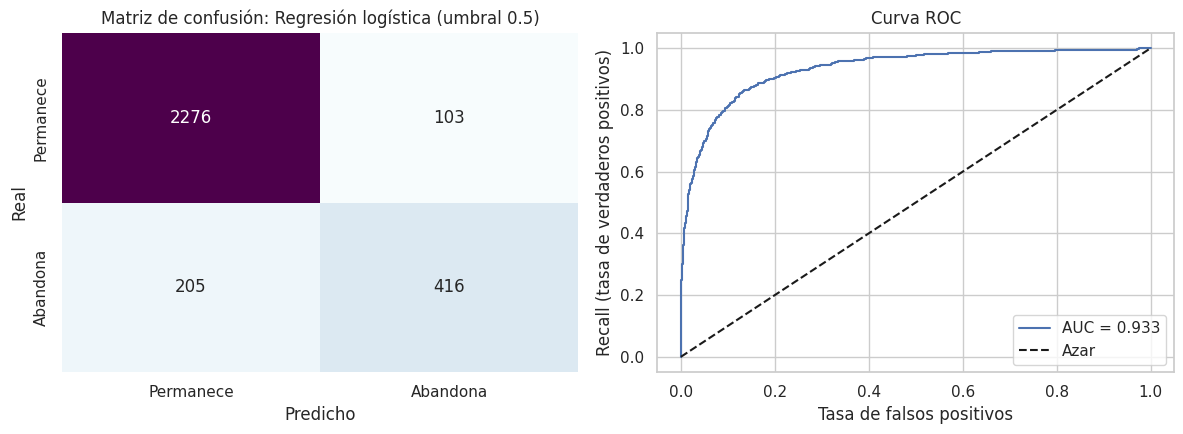

{'Accuracy': 0.8973333333333333,
 'Precisión': 0.8015414258188824,
 'Recall': 0.6698872785829307,
 'F1': 0.7298245614035088,
 'AUC-ROC': np.float64(0.9329032415276178),
 'AUC-PR': np.float64(0.8318018499475857)}

In [23]:
modelo_lr = pipeline_logistica()
modelo_lr.fit(X_train, y_train)

proba_lr = modelo_lr.predict_proba(X_test)[:, 1]
evaluar_modelo('Regresión logística', y_test, proba_lr)

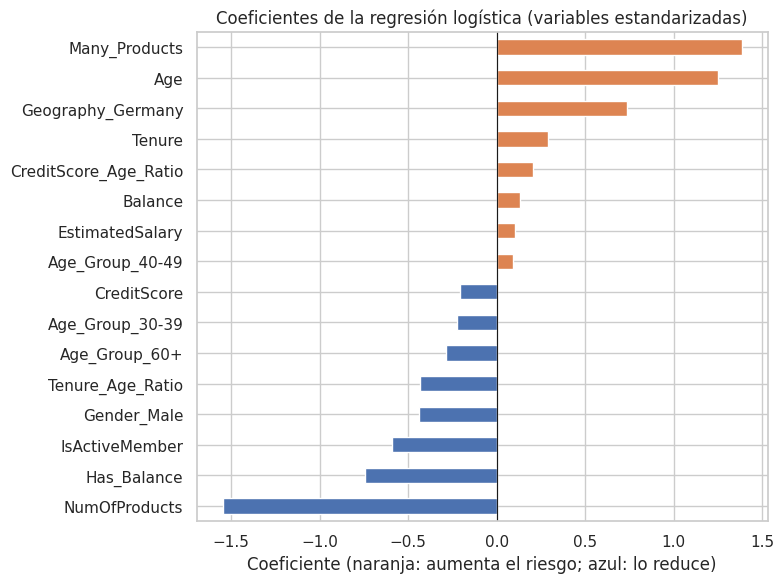

In [24]:
coef = pd.Series(modelo_lr.named_steps['clf'].coef_[0], index=X_train.columns).sort_values()
extremos = pd.concat([coef.head(8), coef.tail(8)])
extremos.plot(kind='barh', figsize=(8, 6), color=['#4C72B0' if v < 0 else '#DD8452' for v in extremos])
plt.axvline(0, color='k', lw=0.8)
plt.title('Coeficientes de la regresión logística (variables estandarizadas)')
plt.xlabel('Coeficiente (naranja: aumenta el riesgo; azul: lo reduce)')
plt.tight_layout(); plt.show()

**Interpretación.** Las barras naranjas son variables que **aumentan** la probabilidad de abandono y las azules la **reducen**. Contrasta esto con el EDA: ¿coincide el signo de cada coeficiente con lo que viste en los gráficos? Observa también el balance entre **precisión y recall** en el reporte: con un umbral de 0.5 y una clase minoritaria, lo habitual es que el modelo sea conservador (alta precisión, recall más bajo). Más adelante ajustaremos el umbral con criterio económico.

## 8.2 Árbol de decisión

Un árbol divide los datos con preguntas sucesivas del tipo "¿`NumOfProducts` ≥ 3?", buscando que cada subgrupo sea lo más **homogéneo** posible respecto a la clase.

**Componentes:** nodo raíz (todos los datos), nodos internos (condiciones), ramas (resultado de la condición) y hojas (la clase o probabilidad final).

**Medidas de impureza** (para elegir la mejor pregunta en cada nodo):

$$ \text{Entropía: } H(S) = -\sum_{i} p_i \log_2(p_i) \qquad \text{Gini: } G(S) = 1 - \sum_{i} p_i^2 $$

La **ganancia de información** es la reducción de impureza al dividir el conjunto $S$ con un atributo $A$:

$$ Gain(S, A) = H(S) - \sum_{v \in A} \frac{|S_v|}{|S|} H(S_v) $$

**Hiperparámetros clave:** `max_depth` (profundidad máxima) y `min_samples_leaf` (mínimo de clientes por hoja) controlan la complejidad. Un árbol sin límites **memoriza** los datos de entrenamiento (sobreajuste).

**Ventajas:** muy interpretable, no requiere estandarizar, captura relaciones no lineales e interacciones. **Limitaciones:** inestable (pequeños cambios en los datos cambian el árbol) y propenso al sobreajuste.

              precision    recall  f1-score   support

   Permanece       0.91      0.96      0.93      2379
    Abandona       0.80      0.65      0.72       621

    accuracy                           0.89      3000
   macro avg       0.86      0.80      0.83      3000
weighted avg       0.89      0.89      0.89      3000



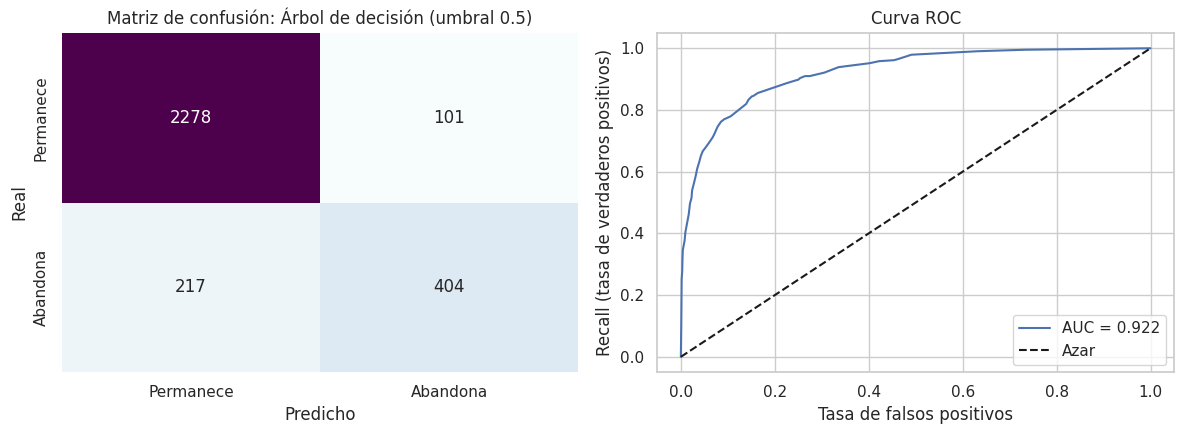

{'Accuracy': 0.894,
 'Precisión': 0.8,
 'Recall': 0.6505636070853462,
 'F1': 0.7175843694493783,
 'AUC-ROC': np.float64(0.9222524789167696),
 'AUC-PR': np.float64(0.7964695989545711)}

In [27]:
arbol = DecisionTreeClassifier(criterion='entropy',
                               max_depth=6,
                               min_samples_leaf=50,
                               min_samples_split=10,
                               random_state=RANDOM_STATE)
arbol.fit(X_train, y_train)

proba_dt = arbol.predict_proba(X_test)[:, 1]
evaluar_modelo('Árbol de decisión', y_test, proba_dt)

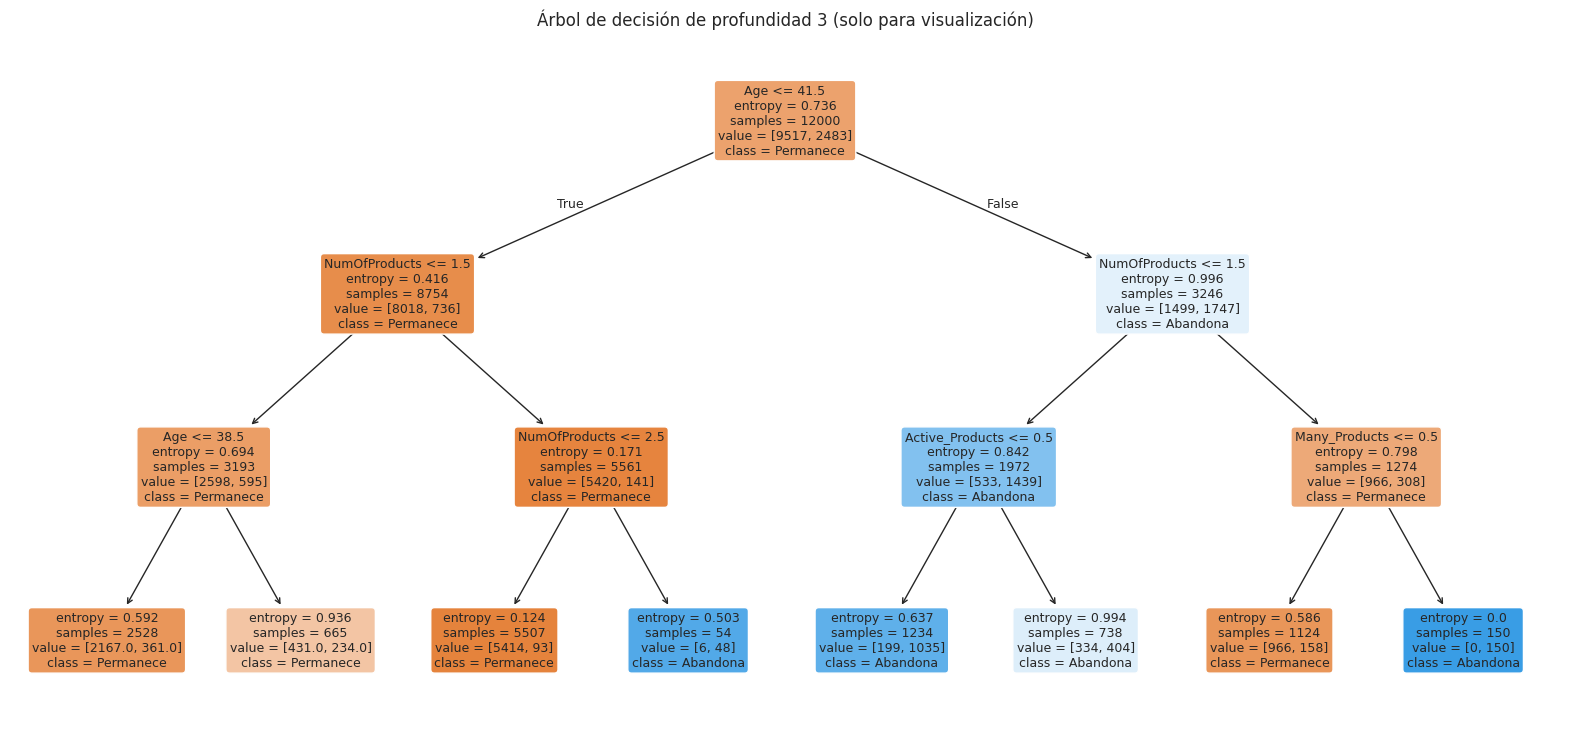

In [28]:
# Para poder leerlo, dibujamos un árbol pequeño (profundidad 3) con el mismo criterio
arbol_vis = DecisionTreeClassifier(criterion='entropy',
                                   max_depth=3,
                                   min_samples_leaf=50,
                                   random_state=RANDOM_STATE)
arbol_vis.fit(X_train, y_train)

plt.figure(figsize=(20, 9))
plot_tree(arbol_vis, feature_names=list(X_train.columns), class_names=['Permanece', 'Abandona'],
          filled=True, rounded=True, fontsize=9)
plt.title('Árbol de decisión de profundidad 3 (solo para visualización)')
plt.show()

**Interpretación.** Lee el árbol de arriba hacia abajo: la variable de la **raíz** es la que mejor separa a los clientes, y los colores muestran la clase dominante en cada nodo (naranja: abandona, azul: permanece). Cada camino de la raíz a una hoja es una **regla de negocio** legible, por ejemplo "si tiene 3 o más productos y es de cierto grupo de edad, el riesgo es alto". El modelo evaluado arriba es más profundo (6 niveles), por eso rinde mejor que este árbol de ilustración.

## 8.3 Random Forest

Un Random Forest combina **muchos árboles** entrenados de forma independiente y promedia sus votos, lo que reduce la inestabilidad de un árbol individual.

**Dos fuentes de aleatoriedad:**
1. **Bagging (*bootstrap aggregating*):** cada árbol se entrena con una muestra aleatoria **con reemplazo** de los datos.
2. **Subconjunto aleatorio de variables:** en cada división solo se consideran algunas variables elegidas al azar, lo que **descorrelaciona** los árboles.

**Predicción:** si $T$ es el número de árboles, la probabilidad final es el promedio:

$$ \hat{p}(x) = \frac{1}{T} \sum_{t=1}^{T} p_t(x) $$

**Hiperparámetros clave:** `n_estimators` (número de árboles), `max_depth`, `min_samples_leaf`, `max_features`.

**Ventajas:** robusto al sobreajuste, buen desempeño sin mucho ajuste, ofrece importancia de variables. **Limitaciones:** menos interpretable que un solo árbol y más pesado en memoria y tiempo.

              precision    recall  f1-score   support

   Permanece       0.91      0.96      0.94      2379
    Abandona       0.82      0.65      0.72       621

    accuracy                           0.90      3000
   macro avg       0.86      0.81      0.83      3000
weighted avg       0.89      0.90      0.89      3000



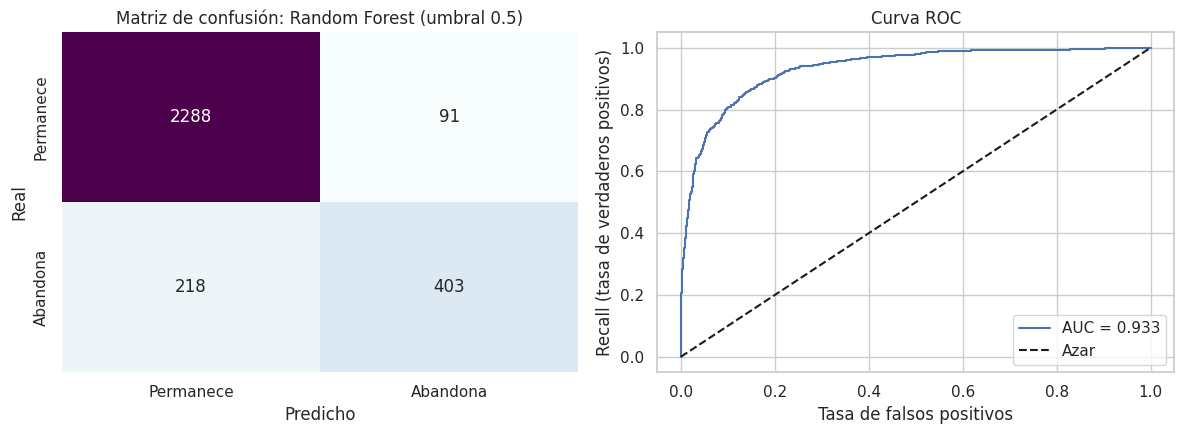

{'Accuracy': 0.897,
 'Precisión': 0.8157894736842105,
 'Recall': 0.6489533011272142,
 'F1': 0.7228699551569506,
 'AUC-ROC': np.float64(0.9333310319292738),
 'AUC-PR': np.float64(0.8203172434580995)}

In [31]:
bosque = RandomForestClassifier(n_estimators=200,
                                max_depth=12,
                                min_samples_leaf=20,
                                n_jobs=-1, random_state=RANDOM_STATE)
bosque.fit(X_train, y_train)

proba_rf = bosque.predict_proba(X_test)[:, 1]
evaluar_modelo('Random Forest', y_test, proba_rf)

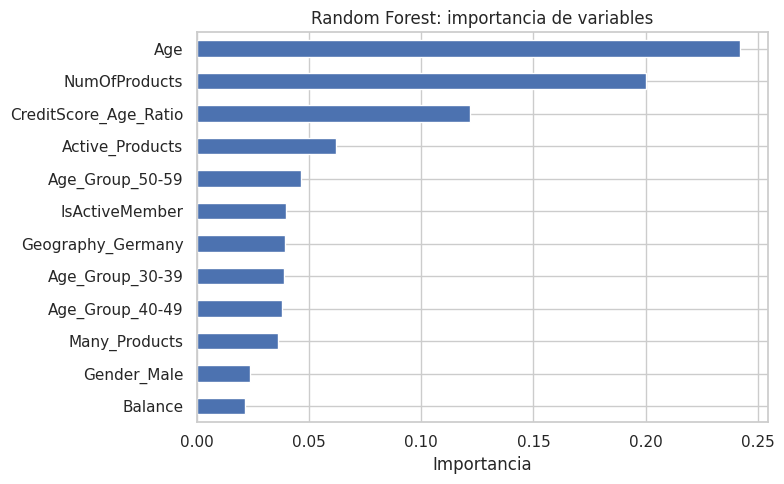

In [32]:
graficar_importancias(X_train.columns, bosque.feature_importances_, 'Random Forest: importancia de variables')

**Interpretación.** La importancia indica cuánto contribuye cada variable a reducir la impureza en todo el bosque. Compárala con los hallazgos del EDA y con los coeficientes de la regresión logística: ¿coinciden las variables más relevantes? Atención: esta importancia puede favorecer a las variables continuas con muchos valores distintos; es una guía, no una verdad absoluta.

## 8.4 XGBoost (Extreme Gradient Boosting)

A diferencia del Random Forest (árboles independientes), el **boosting** entrena árboles **en secuencia**: cada árbol nuevo intenta **corregir los errores** del conjunto anterior.

**Predicción acumulada** tras $t$ árboles, con tasa de aprendizaje $\eta$:

$$ \hat{y}^{(t)}_i = \hat{y}^{(t-1)}_i + \eta \, f_t(x_i) $$

**Objetivo regularizado** que se minimiza en cada paso:

$$ Obj^{(t)} = \sum_{i=1}^{n} L\left(y_i, \hat{y}^{(t)}_i\right) + \sum_{k=1}^{t} \Omega(f_k) \qquad \Omega(f) = \gamma T_f + \frac{1}{2} \lambda \sum_{j} w_j^2 $$

donde $T_f$ es el número de hojas del árbol y $w_j$ el valor de cada hoja. Para clasificación binaria con pérdida logarítmica, el **gradiente** y el **hessiano** de cada observación son:

$$ g_i = p_i - y_i \qquad h_i = p_i (1 - p_i) $$

**Hiperparámetros clave:** `n_estimators`, `learning_rate` ($\eta$), `max_depth`, `min_child_weight`, `subsample`, `colsample_bytree`.

**Parada temprana (*early stopping*).** En lugar de fijar el número de árboles a ciegas, entrenamos con muchos y **nos detenemos cuando el desempeño en validación deja de mejorar**. Esto evita el sobreajuste y nos permite dibujar las **curvas de entrenamiento** (sección 10).

**Ventajas:** suele ser el mejor modelo en datos tabulares, maneja valores faltantes y regulariza. **Limitaciones:** más hiperparámetros que ajustar y menos interpretable.

              precision    recall  f1-score   support

   Permanece       0.92      0.95      0.93      2379
    Abandona       0.77      0.68      0.72       621

    accuracy                           0.89      3000
   macro avg       0.85      0.81      0.83      3000
weighted avg       0.89      0.89      0.89      3000



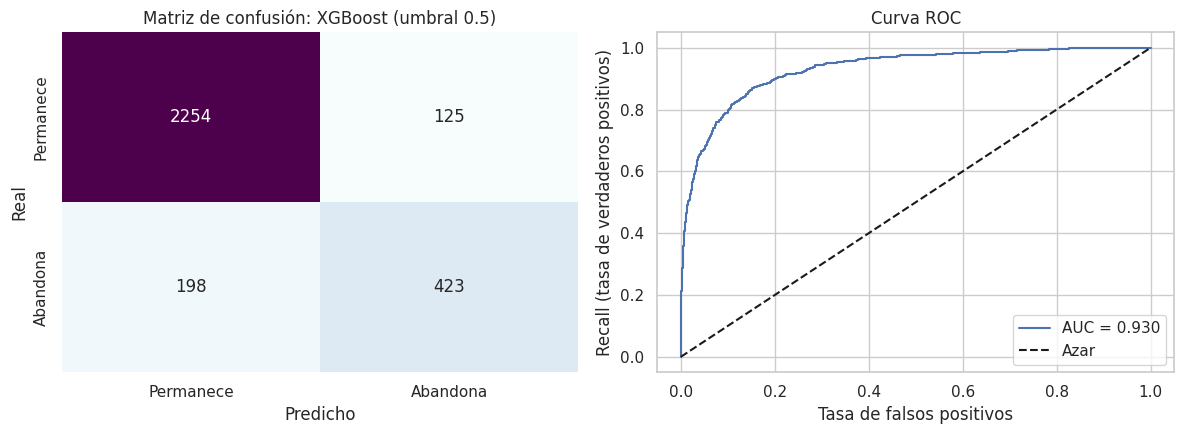

{'Accuracy': 0.8923333333333333,
 'Precisión': 0.7718978102189781,
 'Recall': 0.6811594202898551,
 'F1': 0.7236954662104362,
 'AUC-ROC': np.float64(0.9300853753217737),
 'AUC-PR': np.float64(0.8208365995362017)}

In [33]:
xgb_final = XGBClassifier(n_estimators=1000,
                          learning_rate=0.05,
                          max_depth=5, n_jobs=-1,
                          random_state=RANDOM_STATE)
xgb_final.fit(X_train, y_train)

proba_xgb = xgb_final.predict_proba(X_test)[:, 1]
evaluar_modelo('XGBoost', y_test, proba_xgb)

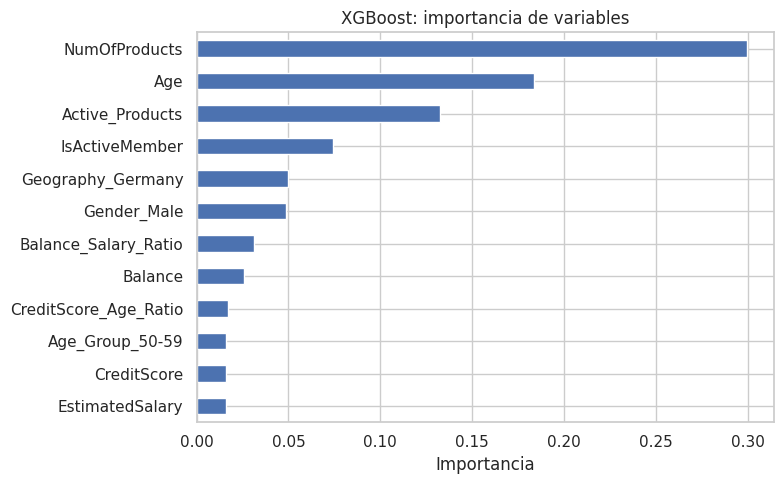

In [34]:
graficar_importancias(X_train.columns, xgb_final.feature_importances_, 'XGBoost: importancia de variables')

**Interpretación.** Compara la curva ROC y el AUC con los modelos anteriores. XGBoost corrige errores de forma progresiva, por lo que suele capturar interacciones complejas que el árbol único y la regresión logística no ven. Observa si las variables más importantes cambian respecto al Random Forest: distintos algoritmos pueden repartir el "crédito" entre variables correlacionadas de forma diferente.

**Diferencias entre Random Forest y XGBoost**

| Aspecto | Random Forest | XGBoost |
|---|---|---|
| Construcción | Árboles **independientes** (paralelos) | Árboles **secuenciales**, cada uno corrige al anterior |
| Qué reduce | Principalmente la **varianza** | Principalmente el **sesgo** (y con regularización, la varianza) |
| Árboles típicos | Profundos | Poco profundos |
| Regularización | Indirecta (aleatoriedad) | Explícita ($\gamma$, $\lambda$, `learning_rate`, `subsample`) |
| Sensibilidad a hiperparámetros | Baja | Alta |

## 8.5 Red neuronal (perceptrón multicapa)

Una red neuronal apila capas de **neuronas**. Cada neurona calcula una combinación lineal de sus entradas y le aplica una **función de activación** no lineal:

$$ a = \phi(w^\top x + b) \qquad \text{ReLU: } \phi(z) = \max(0, z) \qquad \text{Sigmoide (salida): } \sigma(z) = \frac{1}{1 + e^{-z}} $$

La capa de salida con una neurona sigmoide produce la **probabilidad de abandono**. La red se entrena minimizando la **entropía cruzada binaria** (la misma pérdida de la regresión logística) mediante **descenso de gradiente** y **retropropagación**, que es justo lo que practicaste en el taller de matemáticas para IA:

$$ w \leftarrow w - \eta \, \frac{\partial L}{\partial w} $$

**Regularización:** `Dropout` apaga neuronas al azar durante el entrenamiento para evitar la memorización, y la **parada temprana** detiene el entrenamiento cuando la pérdida de validación deja de mejorar.

**Requiere variables estandarizadas.** **Ventajas:** flexible, puede aprender relaciones muy complejas. **Limitaciones:** en datos tabulares pequeños o medianos rara vez supera a XGBoost, es menos interpretable y más sensible a la escala y a los hiperparámetros.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,521 (13.75 KB)

 Trainable params: 3,521 (13.75 KB)

 Non-trainable params: 0 (0.00 B)

Épocas entrenadas: 37
              precision    recall  f1-score   support

   Permanece       0.92      0.96      0.94      2379
    Abandona       0.80      0.69      0.74       621

    accuracy                           0.90      3000
   macro avg       0.86      0.82      0.84      3000
weighted avg       0.90      0.90      0.90      3000



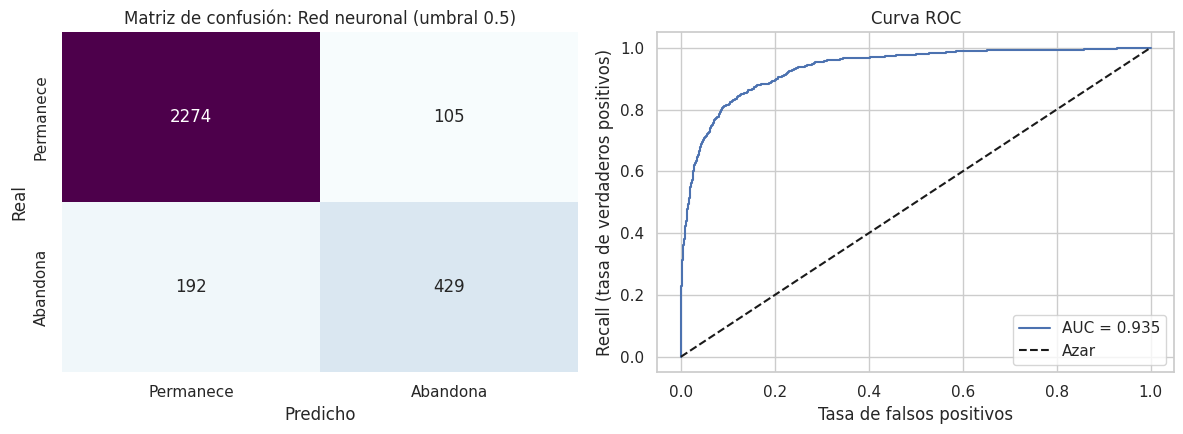

{'Accuracy': 0.901,
 'Precisión': 0.8033707865168539,
 'Recall': 0.6908212560386473,
 'F1': 0.7428571428571429,
 'AUC-ROC': np.float64(0.934753841144908),
 'AUC-PR': np.float64(0.8301183892324303)}

In [35]:
import tensorflow as tf
tf.keras.utils.set_random_seed(RANDOM_STATE)

# Estandarización: se ajusta SOLO con el entrenamiento
escalador = StandardScaler().fit(X_tr)
X_tr_s, X_val_s, X_test_s = escalador.transform(X_tr), escalador.transform(X_val), escalador.transform(X_test)

red = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_tr_s.shape[1],)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1, activation='sigmoid'),
])
red.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
            loss='binary_crossentropy',
            metrics=[tf.keras.metrics.AUC(name='auc')])
red.summary()

parada = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)
historia = red.fit(X_tr_s, y_tr, validation_data=(X_val_s, y_val), epochs=60, batch_size=512,
                   callbacks=[parada], verbose=0)
print(f'Épocas entrenadas: {len(historia.history["loss"])}')

proba_nn = red.predict(X_test_s, verbose=0).ravel()
evaluar_modelo('Red neuronal', y_test, proba_nn)

**Interpretación.** Las curvas de pérdida de esta red por época (sección 10) permiten ver cuándo empieza a sobreajustar. Compara su AUC con el de XGBoost: en datos tabulares como estos, los modelos de *boosting* suelen igualar o superar a las redes con mucho menos esfuerzo de ajuste.

# 9. Comparación de modelos (conjunto de prueba)

,Accuracy,Precisión,Recall,F1,AUC-ROC,AUC-PR
Red neuronal,0.9010,0.8034,0.6908,0.7429,0.9348,0.8301
Random Forest,0.8970,0.8158,0.6490,0.7229,0.9333,0.8203
Regresión logística,0.8973,0.8015,0.6699,0.7298,0.9329,0.8318
XGBoost,0.8923,0.7719,0.6812,0.7237,0.9301,0.8208
Árbol de decisión,0.8940,0.8000,0.6506,0.7176,0.9223,0.7965


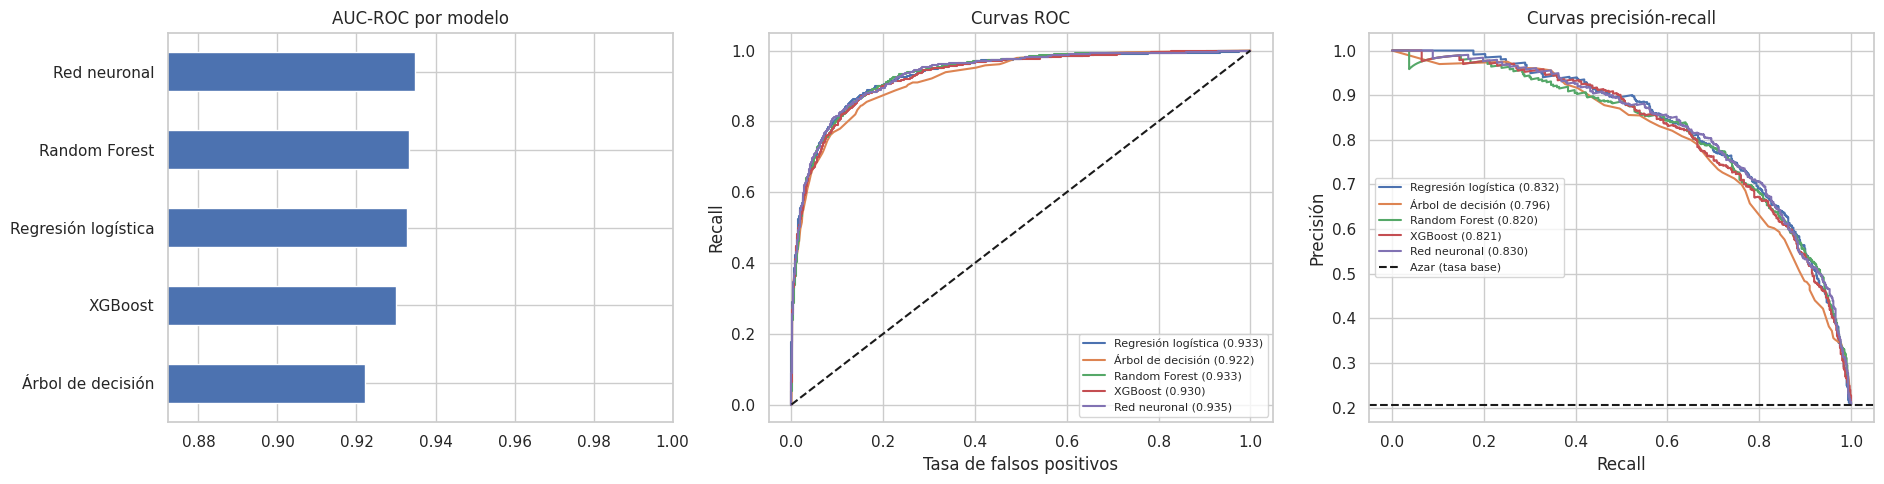

In [36]:
tabla_resultados = pd.DataFrame(resultados).T.sort_values('AUC-ROC', ascending=False)
display(tabla_resultados.round(4))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

tabla_resultados['AUC-ROC'].sort_values().plot(kind='barh', ax=axes[0], color='#4C72B0')
axes[0].set_xlim(tabla_resultados['AUC-ROC'].min() - 0.05, 1)
axes[0].set_title('AUC-ROC por modelo')

for nombre, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[1].plot(fpr, tpr, label=f"{nombre} ({resultados[nombre]['AUC-ROC']:.3f})")
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_xlabel('Tasa de falsos positivos'); axes[1].set_ylabel('Recall')
axes[1].set_title('Curvas ROC'); axes[1].legend(fontsize=8)

for nombre, p in probas.items():
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[2].plot(rec, prec, label=f"{nombre} ({resultados[nombre]['AUC-PR']:.3f})")
axes[2].axhline(y_test.mean(), color='k', ls='--', label='Azar (tasa base)')
axes[2].set_xlabel('Recall'); axes[2].set_ylabel('Precisión')
axes[2].set_title('Curvas precisión-recall'); axes[2].legend(fontsize=8)

plt.tight_layout(); plt.show()

**Cómo leer la comparación.**
- Ordenamos por **AUC-ROC** porque no depende del umbral. Las otras métricas se calcularon con umbral 0.5, así que pueden cambiar mucho si movemos el umbral (sección 11).
- **Curvas ROC**: cuanto más pegada a la esquina superior izquierda, mejor. **Curvas precisión-recall**: muestran qué precisión se logra para cada nivel de recall; la línea punteada es el desempeño de un modelo aleatorio (la tasa base de abandono).
- Si dos modelos tienen AUC muy parecidos, prefiere el **más simple e interpretable**: la mejora de unas milésimas rara vez justifica una mayor complejidad en producción.

# 12. Análisis de sensibilidad de hiperparámetros (XGBoost)

Los **hiperparámetros** no se aprenden de los datos: los fija quien modela. Un **análisis de sensibilidad** varía **un hiperparámetro a la vez**, dejando los demás fijos, y observa cómo cambia el desempeño en entrenamiento y en validación. Sirve para:
- Entender **cuáles hiperparámetros importan más**.
- Detectar la zona de **subajuste** y de **sobreajuste**.
- Elegir valores en una **meseta estable**, no en un pico frágil.

Usamos AUC-ROC sobre el conjunto de **validación** (nunca sobre prueba, para no "filtrar" información del conjunto de prueba al elegir hiperparámetros).

> **Tiempo de ejecución:** esta sección entrena varias decenas de modelos; con el dataset completo puede tardar unos minutos.

In [37]:
from sklearn.base import clone
from numbers import Number

PARAMS_BASE = dict(n_estimators=300,
                   learning_rate=0.05, max_depth=5, min_child_weight=1,
                   subsample=0.8, colsample_bytree=0.8, tree_method='hist', n_jobs=-1,
                   random_state=RANDOM_STATE)

# Modelo base para el análisis de sensibilidad de XGBoost
xgb_base = XGBClassifier(**PARAMS_BASE)

def auc_modelo(modelo, Xa, ya, **kw):
    return roc_auc_score(ya, modelo.predict_proba(Xa, **kw)[:, 1])

def sensibilidad(modelo, param, valores, log_x='auto',
                 X_ent=None, y_ent=None, X_eval=None, y_eval=None):
    """
    Analiza la sensibilidad de un modelo a UN hiperparámetro (los demás quedan fijos).

    modelo  : estimador de scikit-learn o XGBoost (entrenado o no; solo se usan sus hiperparámetros).
    param   : nombre del hiperparámetro. En un Pipeline se usa 'paso__param', p. ej. 'clf__C'.
    valores : lista de valores a evaluar (numéricos o categóricos, p. ej. ['gini', 'entropy'] o None).
    log_x   : 'auto' usa escala logarítmica si los valores cubren dos o más órdenes de magnitud.
    Por defecto entrena con (X_tr, y_tr) y evalúa con (X_val, y_val).
    """
    X_ent = X_tr if X_ent is None else X_ent
    y_ent = y_tr if y_ent is None else y_ent
    X_eval = X_val if X_eval is None else X_eval
    y_eval = y_val if y_eval is None else y_eval

    tr_auc, va_auc = [], []
    for v in valores:
        m = clone(modelo).set_params(**{param: v}).fit(X_ent, y_ent)
        tr_auc.append(auc_modelo(m, X_ent, y_ent))
        va_auc.append(auc_modelo(m, X_eval, y_eval))

    # Eje x: numérico si todos los valores son números; si no, posiciones con etiquetas
    numerico = all(isinstance(v, Number) and not isinstance(v, bool) for v in valores)
    x = list(valores) if numerico else list(range(len(valores)))
    if log_x == 'auto':
        log_x = numerico and min(valores) > 0 and max(valores) / min(valores) >= 100

    mejor = int(np.argmax(va_auc))
    nombre = type(modelo[-1] if isinstance(modelo, Pipeline) else modelo).__name__

    fig, ax = plt.subplots(figsize=(8, 4.8))
    ax.plot(x, tr_auc, marker='o', label='Entrenamiento')
    ax.plot(x, va_auc, marker='o', label='Validación')
    ax.scatter(x[mejor], va_auc[mejor], s=200, facecolors='none', edgecolors='red',
               label=f'Mejor en validación ({valores[mejor]})')
    if log_x:
        ax.set_xscale('log')
    if not numerico:
        ax.set_xticks(x)
        ax.set_xticklabels([str(v) for v in valores])
    ax.set_xlabel(param); ax.set_ylabel('AUC-ROC')
    ax.set_title(f'Sensibilidad de {nombre} a {param}')
    ax.legend(); ax.grid(alpha=0.3)
    plt.show()

    return pd.DataFrame({param: valores,
                         'AUC entrenamiento': tr_auc,
                         'AUC validación': va_auc,
                         'Brecha (sobreajuste)': np.array(tr_auc) - np.array(va_auc)}).round(4)

## 12.1 Profundidad máxima de los árboles (`max_depth`)
Controla la **complejidad** de cada árbol: más profundidad permite capturar interacciones más finas, pero facilita la memorización.

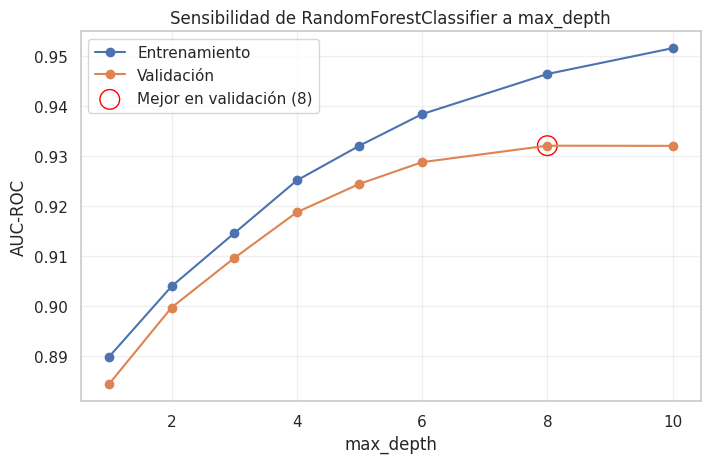

,max_depth,AUC entrenamiento,AUC validación,Brecha (sobreajuste)
0,1,0.8898,0.8844,0.0054
1,2,0.9039,0.8997,0.0042
2,3,0.9145,0.9096,0.0050
3,4,0.9251,0.9187,0.0064
4,5,0.9320,0.9244,0.0076
5,6,0.9384,0.9287,0.0096
6,8,0.9464,0.9320,0.0143
7,10,0.9515,0.9320,0.0195


In [39]:
sens_depth = sensibilidad(bosque, 'max_depth', [1, 2, 3, 4, 5, 6, 8, 10])
sens_depth

## 10 entregas reproducibles para Kaggle

La métrica oficial es AUC-ROC, por lo que las entregas contienen la probabilidad de `Exited=1`, no una clase redondeada. Se comparan diez modelos con una partición estratificada y se ordenan de menor a mayor AUC validado. La entrega 10 es el mejor modelo individual validado; `ensemble_top3.csv` es una alternativa opcional.


In [ ]:
"""Entrenamiento reproducible de diez modelos para la competencia de churn."""

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    AdaBoostClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
OUTPUT_DIR = ROOT / "submissions"


def add_features(frame: pd.DataFrame) -> pd.DataFrame:
    """Adds stable ratios and non-linear terms available at prediction time."""
    data = frame.copy()
    data["AgeSquared"] = data["Age"] ** 2
    data["CreditScoreAge"] = data["CreditScore"] * data["Age"]
    data["BalanceSalaryRatio"] = data["Balance"] / (data["EstimatedSalary"] + 1.0)
    data["IsZeroBalance"] = (data["Balance"] == 0).astype(int)
    data["ProductsPerAge"] = data["NumOfProducts"] / (data["Age"] + 1.0)
    return data.drop(columns=["id", "CustomerId", "Surname"], errors="ignore")


def make_preprocessor(data: pd.DataFrame) -> ColumnTransformer:
    categorical = data.select_dtypes(include=["object", "string", "category"]).columns
    numeric = data.columns.difference(categorical)
    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)
    return ColumnTransformer(
        [
            ("categorical", encoder, categorical.tolist()),
            ("numeric", "passthrough", numeric.tolist()),
        ],
        remainder="drop",
    )


def build_models(preprocessor: ColumnTransformer) -> dict[str, Pipeline]:
    def pipeline(model, scale=False):
        steps = [("preprocess", preprocessor)]
        if scale:
            steps.append(("scale", StandardScaler()))
        steps.append(("model", model))
        return Pipeline(steps)

    return {
        "01_logistic_regression": pipeline(
            LogisticRegression(max_iter=1500, C=0.5, class_weight="balanced"),
            scale=True,
        ),
        "02_knn": pipeline(
            KNeighborsClassifier(n_neighbors=75, weights="distance", p=2),
            scale=True,
        ),
        "03_decision_tree": pipeline(
            DecisionTreeClassifier(
                max_depth=5,
                min_samples_leaf=40,
                class_weight="balanced",
                random_state=RANDOM_STATE,
            )
        ),
        "04_random_forest": pipeline(
            RandomForestClassifier(
                n_estimators=500,
                max_depth=8,
                min_samples_leaf=8,
                max_features=0.8,
                class_weight="balanced_subsample",
                n_jobs=-1,
                random_state=RANDOM_STATE,
            )
        ),
        "05_extra_trees": pipeline(
            ExtraTreesClassifier(
                n_estimators=500,
                max_depth=12,
                min_samples_leaf=5,
                max_features=0.9,
                class_weight="balanced",
                n_jobs=-1,
                random_state=RANDOM_STATE,
            )
        ),
        "06_adaboost": pipeline(
            AdaBoostClassifier(n_estimators=300, learning_rate=0.03, random_state=RANDOM_STATE)
        ),
        "07_hist_gradient_boosting": pipeline(
            HistGradientBoostingClassifier(
                max_iter=300,
                learning_rate=0.05,
                max_leaf_nodes=15,
                l2_regularization=2,
                min_samples_leaf=30,
                random_state=RANDOM_STATE,
            )
        ),
        "08_gradient_boosting": pipeline(
            GradientBoostingClassifier(
                n_estimators=300,
                learning_rate=0.03,
                max_depth=3,
                min_samples_leaf=20,
                subsample=0.85,
                random_state=RANDOM_STATE,
            )
        ),
        "09_xgboost": pipeline(
            XGBClassifier(
                n_estimators=700,
                max_depth=4,
                learning_rate=0.025,
                subsample=0.85,
                colsample_bytree=0.85,
                min_child_weight=8,
                reg_lambda=5,
                reg_alpha=0.1,
                objective="binary:logistic",
                eval_metric="auc",
                n_jobs=-1,
                random_state=RANDOM_STATE,
            )
        ),
        "10_lightgbm": pipeline(
            LGBMClassifier(
                n_estimators=700,
                num_leaves=20,
                max_depth=6,
                learning_rate=0.025,
                min_child_samples=35,
                subsample=0.85,
                colsample_bytree=0.85,
                reg_lambda=5,
                reg_alpha=0.1,
                verbosity=-1,
                n_jobs=-1,
                random_state=RANDOM_STATE,
            )
        ),
    }


def main() -> None:
    train = pd.read_csv(ROOT / "train.csv")
    test = pd.read_csv(ROOT / "test.csv")
    sample = pd.read_csv(ROOT / "sample_submission.csv")

    y = train.pop("Exited").astype(int)
    X = add_features(train)
    X_test = add_features(test)
    X_train, X_valid, y_train, y_valid = train_test_split(
        X, y, test_size=0.22, stratify=y, random_state=RANDOM_STATE
    )

    OUTPUT_DIR.mkdir(exist_ok=True)
    records = []
    predictions = {}
    for name, model in build_models(make_preprocessor(X)).items():
        model.fit(X_train, y_train)
        valid_probability = model.predict_proba(X_valid)[:, 1]
        valid_auc = roc_auc_score(y_valid, valid_probability)
        valid_accuracy = accuracy_score(y_valid, valid_probability >= 0.5)
        model.fit(X, y)
        test_probability = model.predict_proba(X_test)[:, 1]
        predictions[name] = test_probability
        submission = sample.copy()
        submission["Exited"] = test_probability
        submission.to_csv(OUTPUT_DIR / f"{name}.csv", index=False)
        records.append(
            {
                "model": name,
                "validation_auc": valid_auc,
                "validation_accuracy": valid_accuracy,
            }
        )

    scores = pd.DataFrame(records).sort_values("validation_auc").reset_index(drop=True)
    scores.insert(0, "delivery", np.arange(1, len(scores) + 1))
    scores.to_csv(OUTPUT_DIR / "validation_scores.csv", index=False)

    top_models = scores.nlargest(3, "validation_auc")["model"]
    ensemble_probability = np.mean([predictions[name] for name in top_models], axis=0)
    ensemble = sample.copy()
    ensemble["Exited"] = ensemble_probability
    ensemble.to_csv(OUTPUT_DIR / "ensemble_top3.csv", index=False)
    print(scores.to_string(index=False))
    print(f"\nGenerated {len(predictions) + 1} submission files in {OUTPUT_DIR}")


if __name__ == "__main__":
    main()
